# Interpretable Biodegradability Screening — Final Notebook

**Question:** can a small, readable optimal classification tree (OCT) predict ready biodegradability nearly as well as more flexible models?

This notebook covers **CART, OCT and logistic regression**. OCT-H, random forest and XGBoost are run separately by teammates with the same split and folds.

| Part | What happens | Data |
|---|---|---|
| 1 | Load the stratified split | train + val = development set (844), test (211) |
| 2 | Correlation check of the 41 descriptors | development set |
| 3 | Settings | — |
| 4 | Stratified 5-fold cross-validation folds | development set |
| 5 | Sparse feature selection at k = 3, 5, 10 (plus all 41) | development set |
| 6 | Models and cross-validated tuning | development set |
| 7 | Cross-validation results, compared **within each sparsity level**, with ROC and NRB-first views | development set |
| 7b | **Depth trade-off:** what each extra tree level buys | development set |
| 8 | **Final parameters selected for every model** | — |
| 9 | **Test evaluation, run once** | test |

**Workflow (standard k-fold):** the test set is set aside first. On the 844 development chemicals, every candidate setting is scored by 5-fold cross-validation (fit on 4 folds, score on the 5th, average). The chosen setting is then refit on all 844 chemicals, and that final model is evaluated once on test.

**What we compare:** models are compared only at the **same sparsity level** (3, 5, 10 or all 41 descriptors), never across levels.

**What we maximize:** settings are chosen by mean cross-validated **AUC** (how well a model ranks NRB above RB). Results are reported with **balanced accuracy** (mean of NRB recall and RB specificity), because plain accuracy is misleading: always predicting NRB already scores 66%.

**NRB-first view:** missing an NRB chemical (clearing a persistent chemical) is the costlier screening mistake. So every model is also reported at a **precautionary operating point**: the threshold that catches at least 90% of NRB chemicals, and how many RB chemicals each model still clears correctly there.

**Figures** are saved to a `figures/` folder for the report.

---
## Part 1 — Load the stratified split

Files made by our Python split script (60/20/20, stratified by class, duplicate descriptor rows kept together, seed 2026). Training and validation are combined into one **development set**, since cross-validation replaces the separate validation set. y = 1 means NRB.

In [1]:
using CSV, DataFrames, Statistics, LinearAlgebra, Random
# IAI is preloaded by the IAI Julia kernel; if `IAI` is not defined, run: using IAI

const DESCRIPTORS = [
    "SpMax_L", "J_Dz(e)", "nHM", "F01[N-N]", "F04[C-N]", "NssssC", "nCb-",
    "C%", "nCp", "nO", "F03[C-N]", "SdssC", "HyWi_B(m)", "LOC", "SM6_L",
    "F03[C-O]", "Me", "Mi", "nN-N", "nArNO2", "nCRX3", "SpPosA_B(p)", "nCIR",
    "B01[C-Br]", "B03[C-Cl]", "N-073", "SpMax_A", "Psi_i_1d", "B04[C-Br]",
    "SdO", "TI2_L", "nCrt", "C-026", "F02[C-N]", "nHDon", "SpMax_B(m)",
    "Psi_i_A", "nN", "SM6_B(m)", "nArCOOR", "nX",
]

function read_part(path)
    d = CSV.read(path, DataFrame; delim = ';', header = false)
    @assert ncol(d) == 42 "$path has $(ncol(d)) columns"
    rename!(d, vcat(DESCRIPTORS, "class"))
    d.class = String.(strip.(string.(d.class)))
    @assert issubset(Set(d.class), Set(["NRB", "RB"]))
    d
end

dev  = vcat(read_part("biodeg_train_strat.csv"), read_part("biodeg_val_strat.csv"))
test = read_part("biodeg_test_strat.csv")            # untouched until Part 9

X_dev, ys_dev = dev[:, DESCRIPTORS], dev.class        # "NRB"/"RB" labels for IAI
y_dev = Int.(ys_dev .== "NRB")                        # 1 = NRB, for our metrics
X_te,  y_te  = test[:, DESCRIPTORS], Int.(test.class .== "NRB")

for (name, y) in [("development", y_dev), ("test", y_te)]
    println(rpad(name, 12), length(y), " chemicals | NRB ", sum(y), " (",
            round(100 * mean(y), digits = 1), "%) | RB ", length(y) - sum(y))
end

development 844 chemicals | NRB 559 (66.2%) | RB 285
test        211 chemicals | NRB 140 (66.4%) | RB 71


**Plotting setup.** Every figure uses the same color for each model throughout the notebook (OCT blue, CART orange, logistic regression aqua), and is saved to `figures/`.

In [2]:
using Plots          # install once with:  import Pkg; Pkg.add("Plots")
gr()
default(fontfamily = "sans-serif", titlefontsize = 10, guidefontsize = 9, tickfontsize = 8,
        legendfontsize = 8, gridalpha = 0.15, framestyle = :axes, dpi = 150)
const COLORS = Dict("OCT" => "#2a78d6", "CART" => "#eb6834", "Logistic" => "#1baf7a")
const POS_COLOR, NEG_COLOR = "#d6402a", "#2a78d6"     # higher value → more NRB / more RB
mkpath("figures")
setlabel(s) = s == "all" ? "all 41" : "k = $(s[2:end])"

setlabel (generic function with 1 method)

---
## Part 2 — Correlation check (development set only)

Spearman correlation compares the *order* of values, which suits these skewed count descriptors and matches how trees use them. It is computed on the development set only, so the test set influences nothing. This step only describes the data; no descriptor is removed.

In [4]:
function tiedrank(v)
    p, n = sortperm(v), length(v)
    r = Vector{Float64}(undef, n)
    i = 1
    while i <= n
        j = i
        while j < n && v[p[j + 1]] == v[p[i]]
            j += 1
        end
        r[p[i:j]] .= (i + j) / 2
        i = j + 1
    end
    r
end

CORR_CUT = 0.8
nD = length(DESCRIPTORS)
Rk = reduce(hcat, [tiedrank(Float64.(c)) for c in eachcol(X_dev)])
S  = cor(Rk)                                          # Spearman, 41 × 41

# Strongly correlated pairs
strong_pairs = DataFrame(descriptor_1 = String[], descriptor_2 = String[], spearman = Float64[])
for i in 1:nD, j in i+1:nD
    abs(S[i, j]) > CORR_CUT && push!(strong_pairs, (DESCRIPTORS[i], DESCRIPTORS[j], round(S[i, j], digits = 2)))
end
sort!(strong_pairs, :spearman, by = abs, rev = true)
println("Pairs with |Spearman| > $CORR_CUT: ", nrow(strong_pairs))
show(strong_pairs, allrows = true, eltypes = false, summary = false)

# Groups: descriptors linked by a chain of strong correlations
uf_parent = collect(1:nD)
findroot(i) = uf_parent[i] == i ? i : (uf_parent[i] = findroot(uf_parent[i]))
for i in 1:nD, j in i+1:nD
    abs(S[i, j]) > CORR_CUT && (uf_parent[findroot(i)] = findroot(j))
end
groups = Dict{Int,Vector{String}}()
for i in 1:nD
    push!(get!(groups, findroot(i), String[]), DESCRIPTORS[i])
end
println("\n\nGroups of related descriptors:")
for g in sort([g for g in values(groups) if length(g) > 1], by = length, rev = true)
    println("  ", join(g, ", "))
end

Pairs with |Spearman| > 0.8: 17
 Row │ descriptor_1  descriptor_2  spearman 
─────┼──────────────────────────────────────
   1 │ F02[C-N]      nN                0.95
   2 │ F03[C-N]      F02[C-N]          0.91
   3 │ F03[C-N]      nN                0.91
   4 │ SpMax_B(m)    SM6_B(m)          0.91
   5 │ SpMax_L       SpMax_A           0.9
   6 │ F04[C-N]      F03[C-N]          0.9
   7 │ HyWi_B(m)     SM6_B(m)          0.89
   8 │ SM6_L         SpMax_A           0.89
   9 │ SpMax_L       SM6_L             0.88
  10 │ C%            Mi               -0.88
  11 │ nO            F03[C-O]          0.87
  12 │ Me            Psi_i_A           0.87
  13 │ B01[C-Br]     B04[C-Br]         0.86
  14 │ HyWi_B(m)     SM6_L             0.85
  15 │ Mi            SpPosA_B(p)      -0.85
  16 │ F04[C-N]      nN                0.84
  17 │ F04[C-N]      F02[C-N]          0.83

Groups of related descriptors:
  SpMax_L, HyWi_B(m), SM6_L, SpMax_A, SpMax_B(m), SM6_B(m)
  F04[C-N], F03[C-N], F02[C-N], nN
  C%, 

In [5]:
# Each descriptor's association with NRB, and how often it is zero
ry = tiedrank(Float64.(y_dev))
lab = DataFrame(descriptor = DESCRIPTORS,
                spearman_with_NRB = [round(cor(Rk[:, j], ry), digits = 2) for j in 1:nD],
                share_zero = [round(mean(X_dev[!, c] .== 0), digits = 2) for c in DESCRIPTORS])
sort!(lab, :spearman_with_NRB, by = abs, rev = true)
println("Strongest single-descriptor associations with NRB:")
show(first(lab, 10), eltypes = false, summary = false)
println("\n\nDescriptors that are zero for more than 85% of chemicals (presence/absence flags): ",
        join(lab.descriptor[lab.share_zero .> 0.85], ", "))

Strongest single-descriptor associations with NRB:
 Row │ descriptor   spearman_with_NRB  share_zero 
─────┼────────────────────────────────────────────
   1 │ SpMax_B(m)                0.5         0.0
   2 │ SM6_B(m)                  0.46        0.0
   3 │ SpMax_L                   0.45        0.0
   4 │ SpPosA_B(p)               0.44        0.0
   5 │ SpMax_A                   0.44        0.0
   6 │ SM6_L                     0.39        0.0
   7 │ nHM                       0.36        0.69
   8 │ nCb-                      0.36        0.48
   9 │ HyWi_B(m)                 0.36        0.0
  10 │ nCIR                      0.36        0.34

Descriptors that are zero for more than 85% of chemicals (presence/absence flags): NssssC, nArNO2, nArCOOR, F01[N-N], B01[C-Br], nCRX3, N-073, B04[C-Br], nCrt, nN-N


**Figure 1 — correlation heatmap.** Descriptors are ordered so each group of related descriptors sits together; groups show as red blocks along the diagonal.

In [6]:
multi = sort([g for g in values(groups) if length(g) > 1], by = length, rev = true)
ord = vcat([findfirst(==(c), DESCRIPTORS) for g in multi for c in g],
           [i for i in 1:nD if !any(DESCRIPTORS[i] in g for g in multi)])
fig1 = heatmap(DESCRIPTORS[ord], DESCRIPTORS[ord], S[ord, ord];
               c = cgrad([NEG_COLOR, "#f0efec", POS_COLOR]), clims = (-1, 1),
               xrotation = 90, yflip = true, size = (900, 820), tickfontsize = 6,
               colorbar_title = "Spearman correlation",
               title = "Correlation between the 41 descriptors (related groups first)")
savefig(fig1, "figures/fig1_correlation_heatmap.png")
fig1

**Figure 2 — the strongest single descriptors.** Red bars: higher values go with NRB; blue bars: higher values go with RB.

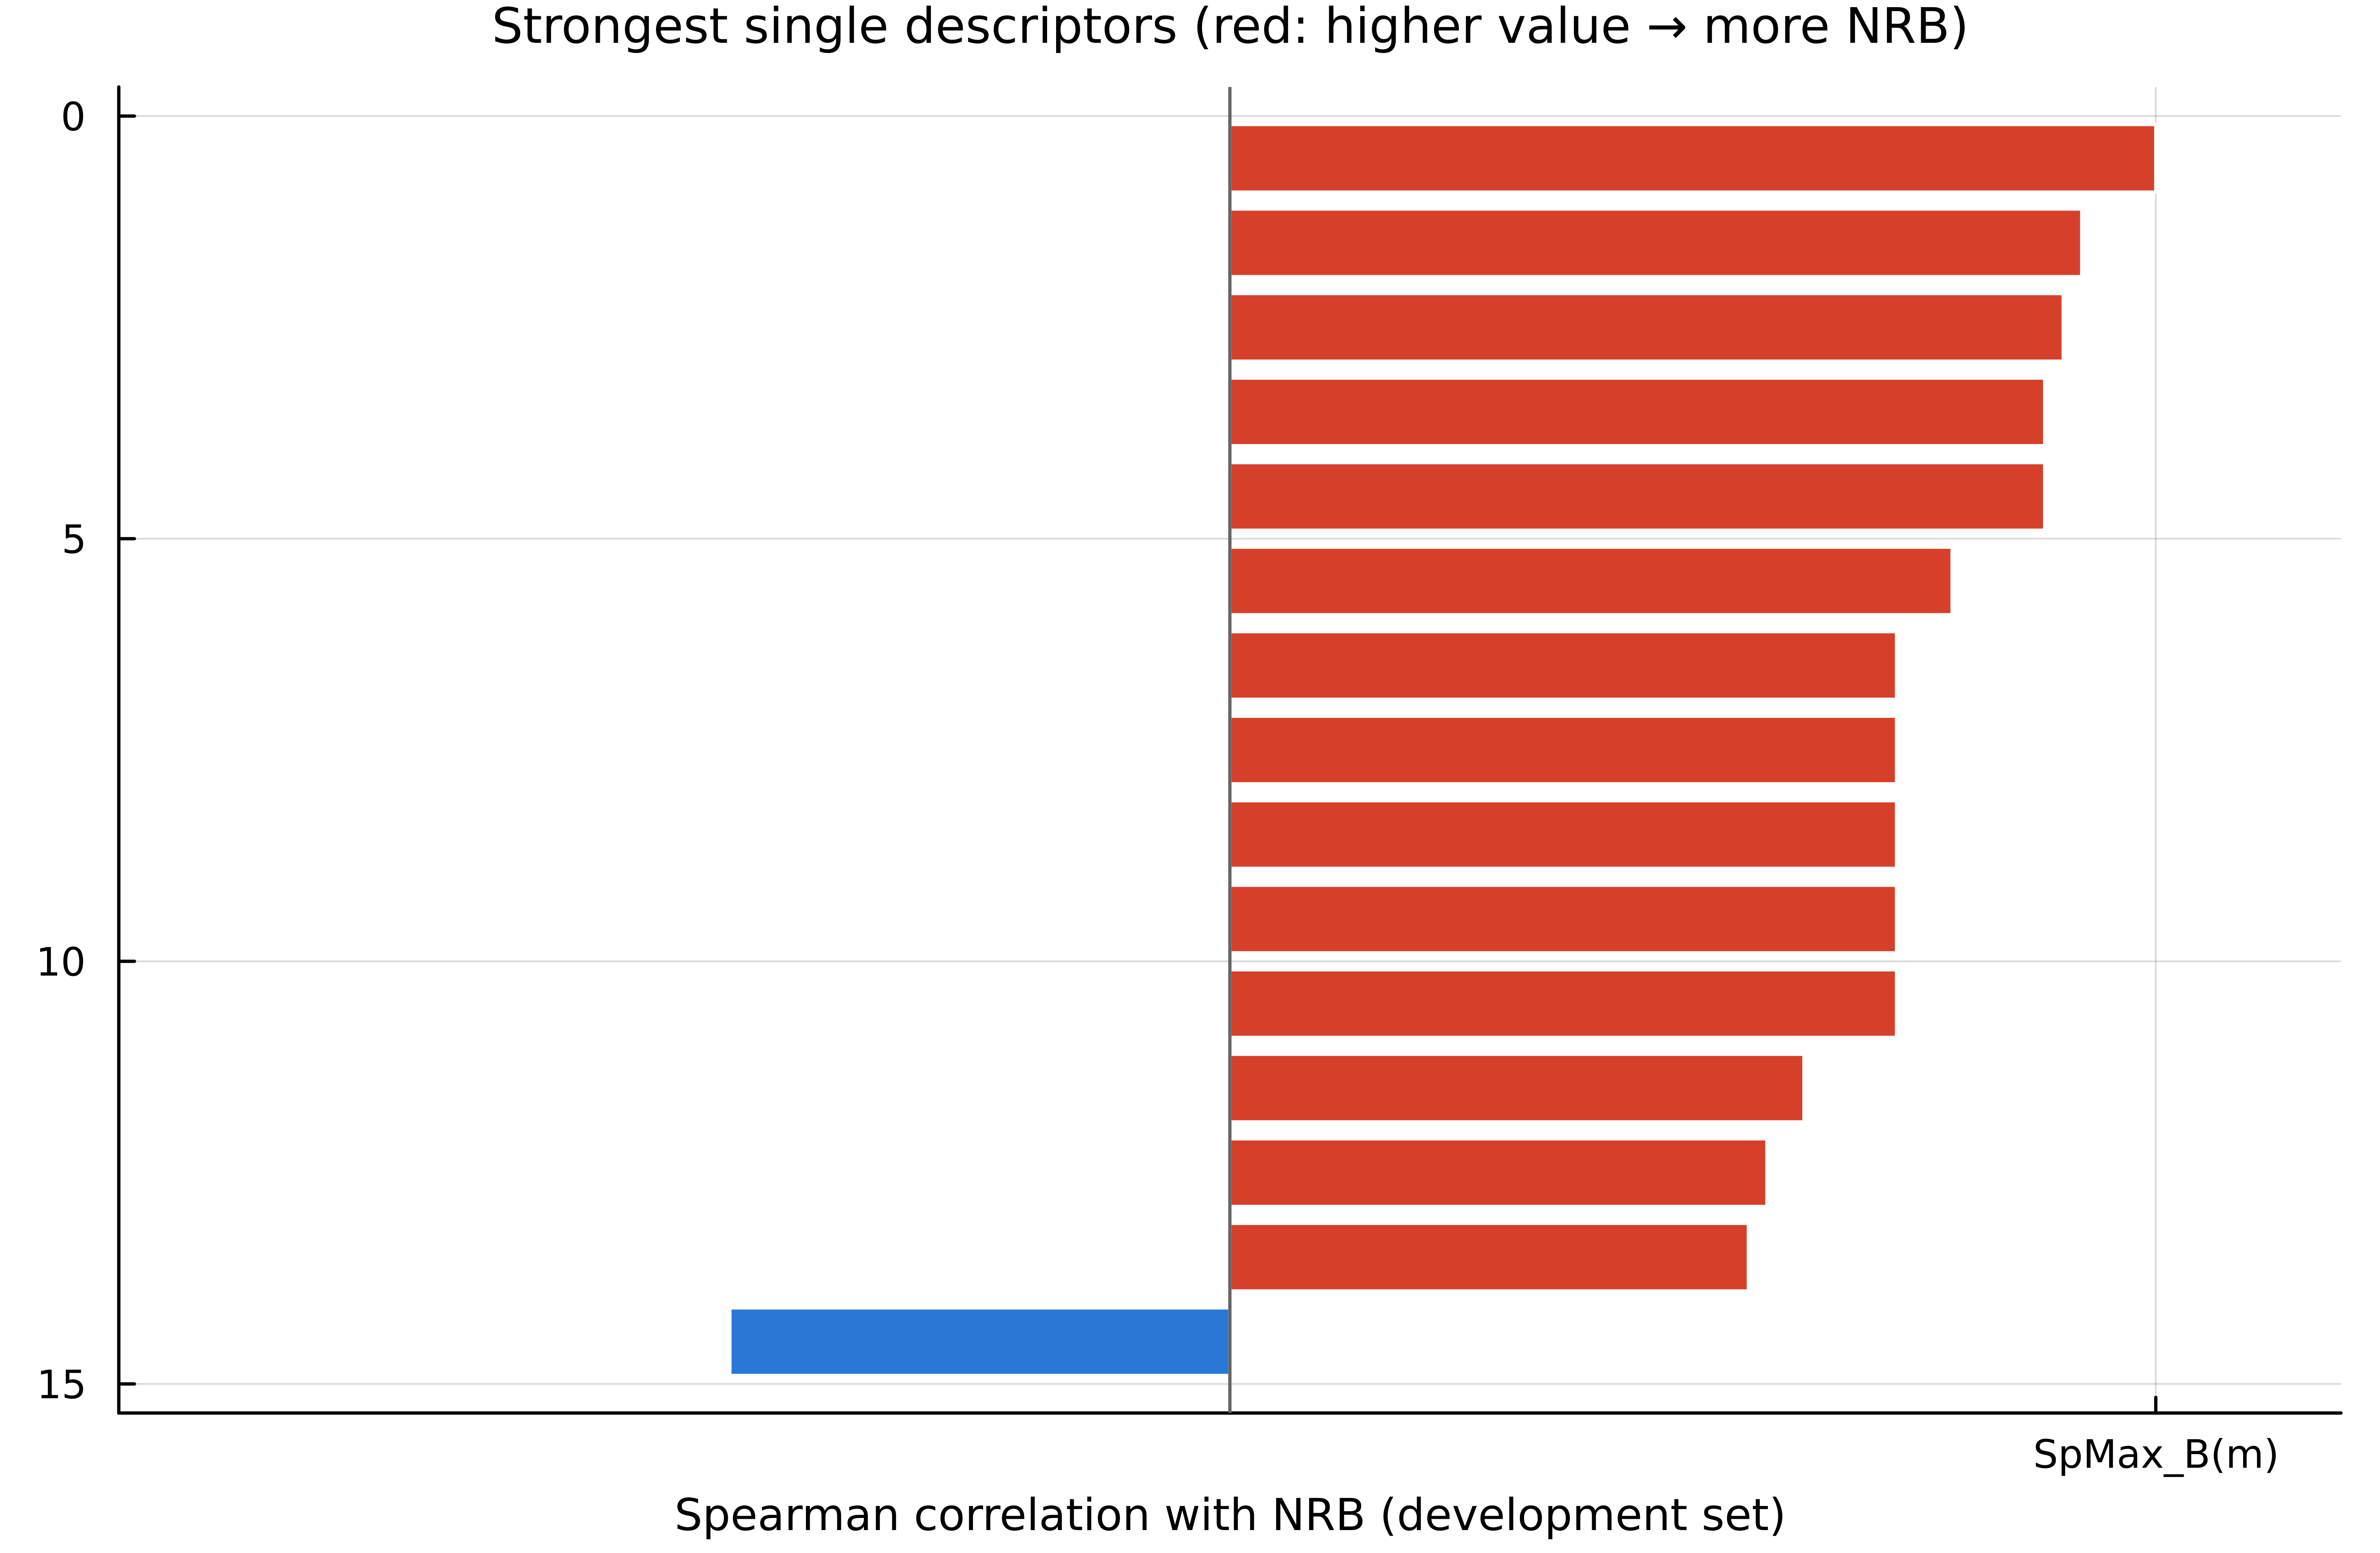

In [7]:
top = first(lab, 15)
fig2 = bar(top.descriptor, top.spearman_with_NRB; orientation = :h, yflip = true,
           color = ifelse.(top.spearman_with_NRB .>= 0, POS_COLOR, NEG_COLOR), linecolor = :white,
           legend = false, xlims = (-0.6, 0.6), size = (720, 470),
           xlabel = "Spearman correlation with NRB (development set)",
           title = "Strongest single descriptors (red: higher value → more NRB)")
vline!(fig2, [0]; color = :gray40, lw = 1)
savefig(fig2, "figures/fig2_descriptor_association.png")
fig2

> ### Insights
> - **17 pairs exceed |0.8|, forming 6 groups** (Figure 1). The two big ones:
>   - a **size / branching group** of spectral indices: SpMax_L, SpMax_A, SM6_L, SpMax_B(m), SM6_B(m), HyWi_B(m);
>   - a **nitrogen group**: nN, F02[C-N], F03[C-N], F04[C-N] (nN vs. F02[C-N]: 0.95). More nitrogen atoms mean more carbon–nitrogen pairs at every distance.
>
>   Smaller groups: C%, Mi and SpPosA_B(p) (composition: more heteroatoms means less carbon, C% vs. Mi −0.88); nO and F03[C-O] (oxygen); Me and Psi_i_A (electronegativity); B01[C-Br] and B04[C-Br] (bromine). Each group is essentially one property measured several ways.
> - **The strongest single descriptor is SpMax_B(m)** (0.50 with NRB), and the top six all come from the size/branching or composition groups (0.39–0.50; Figure 2). Larger, heavier, more branched, more polarizable molecules tend to be NRB. **No descriptor is strong on its own**, so good prediction needs several properties combined.
> - **10 descriptors are zero for more than 85% of chemicals** (e.g. nArNO2, B01[C-Br], nCRX3). They are presence/absence flags for rare structural groups: decisive for the few chemicals that have them, minor on average.
>
> **Why this matters later**
> - **Logistic regression weights inside a group cannot be read one by one:** correlated descriptors share weight arbitrarily.
> - **Sparse selection keeps roughly one representative per group,** and which one it picks is close to arbitrary.
> - **Tree splits should be read as the group's property** (e.g. "size and branching"), not as one exact descriptor.

---
## Part 3 — Settings (change only here)

- **Sparsity levels:** `KS` plus all 41 descriptors.
- **Trees:** CART and OCT search depth 2–4 and minimum leaf size 5/10/20; IAI tunes the complexity penalty `cp` within each fold.
- **Depths:** to try deeper trees, change `TREE_DEPTHS` (e.g. `2:6`); the depth figure in Part 7b updates automatically. Each extra level makes OCT slower.
- **Simplicity rule for trees:** among settings within `TOL_AUC` of the best mean CV AUC, take the shallowest, then the largest leaf size.
- **Logistic regression:** ridge penalty λ from `LAMBDAS`.
- **NRB-first operating point:** `NRB_RECALL_TARGET` is the share of NRB chemicals a model must catch; its threshold is set on out-of-fold predictions and frozen for test.
- **Fold seed:** teammates should use the same `FOLD_SEED` (or the saved `cv_folds.csv`) so all models are scored on identical folds.

In [8]:
SEED      = 1
FOLD_SEED = 2026
N_FOLDS   = 5
KS        = [3, 5, 10]
MODELS    = ["CART", "OCT", "Logistic"]
TREES     = ("CART", "OCT")

TREE_DEPTHS, TREE_MINBUCKETS = 2:4, [5, 10, 20]
TOL_AUC   = 0.01

LAMBDAS   = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
NRB_RECALL_TARGET = 0.90

0.9

---
## Part 4 — Stratified 5-fold cross-validation folds

Each fold gets the same NRB/RB mix (about 66% NRB), and identical descriptor rows always share a fold. Groups of rows are shuffled with a fixed seed and each is placed in the fold that currently has the fewest chemicals of its class.

In [9]:
row_key = [Tuple(r) for r in eachrow(X_dev)]
id_of   = Dict{Any,Int}()
grp     = [get!(id_of, k, length(id_of) + 1) for k in row_key]

fold = zeros(Int, nrow(dev))
rngf = MersenneTwister(FOLD_SEED)
for c in (0, 1)
    gids  = unique(grp[y_dev .== c]); shuffle!(rngf, gids)
    gsize = Dict(g => count(==(g), grp) for g in gids)
    sort!(gids, by = g -> -gsize[g], alg = MergeSort)       # pairs first, then singles
    load = zeros(Int, N_FOLDS)
    for g in gids
        f = argmin(load); fold[grp .== g] .= f; load[f] += gsize[g]
    end
end

@assert all(length(unique(fold[grp .== g])) == 1 for g in unique(grp))
for f in 1:N_FOLDS
    idx = fold .== f
    println("fold $f: ", sum(idx), " chemicals, NRB ", round(100 * mean(y_dev[idx]), digits = 1), "%")
end
CSV.write("cv_folds.csv", DataFrame(dev_row = 1:nrow(dev), class = ys_dev, fold = fold))   # share with teammates

fold 1: 169 chemicals, NRB 66.3%
fold 2: 169 chemicals, NRB 66.3%
fold 3: 169 chemicals, NRB 66.3%
fold 4: 169 chemicals, NRB 66.3%
fold 5: 168 chemicals, NRB 66.1%


"cv_folds.csv"

---
## Part 5 — Sparse feature selection (k = 3, 5, 10)

Least squares on y (1 = NRB) with at most k nonzero coefficients (exact best subset; IAI optimal feature selection), on standardized descriptors. Every model then uses the same descriptor list at each k.

**Note:** selection uses all 844 development chemicals, so cross-validation scores at k = 3, 5, 10 are slightly optimistic. This affects all models equally at a given k, and k is never chosen by cross-validation, so within-k comparisons stay fair. The test set is not involved.

In [10]:
mu_d = [mean(X_dev[!, c]) for c in DESCRIPTORS]
sd_d = [max(std(X_dev[!, c]), 1e-12) for c in DESCRIPTORS]
Z_dev = DataFrame((Matrix{Float64}(X_dev) .- mu_d') ./ sd_d', DESCRIPTORS)

feature_sets = Dict{String,Vector{String}}("all" => DESCRIPTORS)
for k in KS
    ofs = IAI.OptimalFeatureSelectionRegressor(sparsity = k, random_seed = SEED)
    IAI.fit!(ofs, Z_dev, Float64.(y_dev))
    w = Dict(String(f) => b for (f, b) in IAI.get_prediction_weights(ofs)[1])
    feature_sets["k$k"] = [c for c in DESCRIPTORS if get(w, c, 0.0) != 0]
    println(rpad("k = $k", 8), join(feature_sets["k$k"], ", "))
end
SETS = vcat(["k$k" for k in KS], "all")

[ Warning: This copy of Interpretable AI software is for academic purposes only and not for commercial use.


k = 3   SpMax_L, LOC, SpPosA_B(p)
k = 5   SpMax_L, nO, LOC, nN, SM6_B(m)
k = 10  SpMax_L, C%, nO, HyWi_B(m), LOC, F03[C-O], nArNO2, SpPosA_B(p), nN, nArCOOR


4-element Vector{String}:
 "k3"
 "k5"
 "k10"
 "all"

> ### What the selection shows
> | k | Selected | Groups covered |
> |---|---|---|
> | 3 | SpMax_L, LOC, SpPosA_B(p) | size/branching, shape (LOC is in no group), composition |
> | 5 | SpMax_L, SM6_B(m), nN, nO, LOC | size (two from the same group), nitrogen, oxygen, shape |
> | 10 | SpMax_L, HyWi_B(m), C%, SpPosA_B(p), nN, nO, F03[C-O], LOC, nArNO2, nArCOOR | most groups plus two rare flags |
>
> - **At small k it takes about one descriptor per property:** once SpMax_L is in, the rest of its group adds little to a linear fit.
> - **SpMax_B(m), the strongest single descriptor, is never picked,** but its near twin SM6_B(m) (0.91) is at k = 5. The information is used through a stand-in.
> - **At k = 10 it keeps correlated pairs** (nO with F03[C-O], 0.87; SpMax_L with HyWi_B(m)). A correlation limit, as in holistic regression, would block these.
> - **The sets are not nested** (SpPosA_B(p) is in at k = 3, out at 5, back at 10), which is normal for exact best-subset selection.

---
## Part 6 — Models and cross-validated tuning

**Evaluation helpers.** `metrics` turns probabilities into predictions at a threshold. `best_threshold` picks the threshold with the best balanced accuracy on the **out-of-fold** predictions (each chemical predicted by a model that never saw it), which is far more stable than tuning on one small validation set. `recall_threshold` gives the NRB-first operating point. `roc_points` draws ROC curves. `auc` measures ranking.

In [11]:
function metrics(p, y; t = 0.5)
    pred = p .>= t
    rec  = sum(pred .& (y .== 1)) / sum(y .== 1)
    spec = sum(.!pred .& (y .== 0)) / sum(y .== 0)
    (acc = mean(pred .== (y .== 1)), recall = rec, specificity = spec, bal_acc = (rec + spec) / 2,
     nrb_missed = sum(.!pred .& (y .== 1)), rb_cleared = sum(.!pred .& (y .== 0)))
end

function best_threshold(p, y)
    cands = sort(unique(vcat(p, 0.5)))
    cands[argmax([metrics(p, y; t = t).bal_acc for t in cands])]
end

# Highest threshold that still catches at least `target` of NRB (most RB cleared at that recall)
function recall_threshold(p, y, target)
    for t in sort(unique(p), rev = true)
        metrics(p, y; t = t).recall >= target && return t
    end
    minimum(p)
end

# ROC curve points: share of RB flagged (x) vs share of NRB caught (y), over all thresholds
function roc_points(p, y)
    ts = sort(unique(p), rev = true)
    vcat(0.0, [mean(p[y .== 0] .>= t) for t in ts], 1.0), vcat(0.0, [mean(p[y .== 1] .>= t) for t in ts], 1.0)
end

function auc(p, y)
    pos, neg = p[y .== 1], p[y .== 0]
    sum((a > b) + 0.5 * (a == b) for a in pos, b in neg) / (length(pos) * length(neg))
end

auc (generic function with 1 method)

**Trees (CART and OCT).** In each fold, IAI's grid search fits every depth × leaf-size setting on 4 folds, tunes `cp`, and scores it on the 5th fold by AUC. Scores are averaged over the 5 folds, and the simplicity rule picks the setting. Out-of-fold predictions are made with that setting, and the final tree is refit on all 844 chemicals with the median of the per-fold `cp` values. CART is the same learner without local search, so both trees share every setting.

**Depth curve.** For every depth tried, the function also records the best mean CV AUC at that depth, the out-of-fold balanced accuracy, and the average number of leaves, so Part 7b can show what each extra level buys.

In [12]:
tree_kw(kind) = kind == "CART" ? (localsearch = false,) : NamedTuple()

tree_leaves(lnr) = count(n -> IAI.is_leaf(lnr, n), 1:IAI.get_num_nodes(lnr))
tree_features(lnr) = unique([String(IAI.get_split_feature(lnr, n))
                             for n in 1:IAI.get_num_nodes(lnr) if !IAI.is_leaf(lnr, n)])

function cv_tree(fs, kind)
    t0 = time()
    depths, mbs = TREE_DEPTHS, TREE_MINBUCKETS
    per_fold = DataFrame[]
    for f in 1:N_FOLDS
        tr, va = fold .!= f, fold .== f
        grid = IAI.GridSearch(IAI.OptimalTreeClassifier(; random_seed = SEED, tree_kw(kind)...),
                              max_depth = depths, minbucket = mbs)
        IAI.fit!(grid, X_dev[tr, fs], ys_dev[tr], X_dev[va, fs], ys_dev[va], validation_criterion = :auc)
        s = select(IAI.get_grid_result_summary(grid), :max_depth, :minbucket, :cp, :valid_score)
        s.fold .= f
        push!(per_fold, s)
    end
    allf = vcat(per_fold...)
    summ = combine(groupby(allf, [:max_depth, :minbucket]),
                   :valid_score => mean => :cv_auc, :valid_score => std => :cv_sd, :cp => median => :cp)
    ok = sort(summ[summ.cv_auc .>= maximum(summ.cv_auc) - TOL_AUC, :],
              [:max_depth, order(:minbucket, rev = true)])
    ch = ok[1, :]

    oof = zeros(nrow(dev))
    for f in 1:N_FOLDS
        tr, va = fold .!= f, fold .== f
        cpf = allf[(allf.fold .== f) .& (allf.max_depth .== ch.max_depth) .& (allf.minbucket .== ch.minbucket), :cp][1]
        lnr = IAI.OptimalTreeClassifier(; random_seed = SEED, tree_kw(kind)...,
                                        max_depth = ch.max_depth, minbucket = ch.minbucket, cp = cpf)
        IAI.fit!(lnr, X_dev[tr, fs], ys_dev[tr])
        oof[va] = IAI.predict_proba(lnr, X_dev[va, fs])[!, "NRB"]
    end

    # Depth curve: best leaf size at each depth; refit per fold for leaves and out-of-fold scores
    dcurve = DataFrame(max_depth = Int[], minbucket = Int[], cv_auc = Float64[], cv_sd = Float64[],
                       cv_bal_acc = Float64[], mean_leaves = Float64[], chosen = Bool[])
    for d in sort(unique(summ.max_depth))
        sdd = summ[summ.max_depth .== d, :]
        b = sdd[argmax(sdd.cv_auc), :]
        oofd, lv = zeros(nrow(dev)), Int[]
        for f in 1:N_FOLDS
            tr, va = fold .!= f, fold .== f
            cpf = allf[(allf.fold .== f) .& (allf.max_depth .== d) .& (allf.minbucket .== b.minbucket), :cp][1]
            lnr = IAI.OptimalTreeClassifier(; random_seed = SEED, tree_kw(kind)...,
                                            max_depth = d, minbucket = b.minbucket, cp = cpf)
            IAI.fit!(lnr, X_dev[tr, fs], ys_dev[tr])
            oofd[va] = IAI.predict_proba(lnr, X_dev[va, fs])[!, "NRB"]
            push!(lv, tree_leaves(lnr))
        end
        push!(dcurve, (d, b.minbucket, b.cv_auc, b.cv_sd,
                       metrics(oofd, y_dev; t = best_threshold(oofd, y_dev)).bal_acc, mean(lv), d == ch.max_depth))
    end

    params = (max_depth = ch.max_depth, minbucket = ch.minbucket, cp = ch.cp)
    final = IAI.OptimalTreeClassifier(; random_seed = SEED, tree_kw(kind)..., params...)
    IAI.fit!(final, X_dev[:, fs], ys_dev)
    (predict = X -> IAI.predict_proba(final, X[:, fs])[!, "NRB"], model = final,
     settings = "max_depth=$(params.max_depth), minbucket=$(params.minbucket), cp=$(round(params.cp, sigdigits = 3))",
     cv_auc = ch.cv_auc, cv_sd = ch.cv_sd, oof = oof, dcurve = dcurve, time = time() - t0)
end

cv_tree (generic function with 1 method)

**Logistic regression.** For each penalty λ: fit on 4 folds, predict the 5th, repeat for all 5 folds, and average the fold AUCs. The λ with the best mean AUC is refit on all 844 chemicals. Descriptors are standardized using each training part's own means and standard deviations.

In [13]:
function ridge_logit(Z, y, λ; iters = 100)
    A = hcat(ones(size(Z, 1)), Z)
    P = Diagonal(vcat(0.0, fill(λ, size(Z, 2))))
    b = zeros(size(A, 2))
    for _ in 1:iters
        p = 1 ./ (1 .+ exp.(-A * b))
        step = (A' * (A .* (p .* (1 .- p))) + P) \ (A' * (y .- p) - P * b)
        b .+= step
        norm(step) < 1e-8 && break
    end
    b
end

function fit_logit(X, y, fs, prm)
    mu = [mean(X[!, c]) for c in fs]
    sd = [max(std(X[!, c]), 1e-12) for c in fs]
    Z  = (Matrix{Float64}(X[:, fs]) .- mu') ./ sd'
    (b = ridge_logit(Z, Float64.(y), prm.lambda), mu = mu, sd = sd, fs = fs)
end
predict_logit(m, X) = 1 ./ (1 .+ exp.(-(hcat(ones(nrow(X)), (Matrix{Float64}(X[:, m.fs]) .- m.mu') ./ m.sd') * m.b)))

function cv_generic(fs, grid, fitfun, predfun)
    t0 = time()
    res = []
    for prm in grid
        oof, aucs = zeros(nrow(dev)), Float64[]
        for f in 1:N_FOLDS
            tr, va = fold .!= f, fold .== f
            m = fitfun(X_dev[tr, :], y_dev[tr], fs, prm)
            oof[va] = predfun(m, X_dev[va, :])
            push!(aucs, auc(oof[va], y_dev[va]))
        end
        push!(res, (prm = prm, cv_auc = mean(aucs), cv_sd = std(aucs), oof = oof))
    end
    ch = res[argmax([r.cv_auc for r in res])]
    final = fitfun(X_dev, y_dev, fs, ch.prm)
    (predict = X -> predfun(final, X), model = final,
     settings = join(["$k=$v" for (k, v) in pairs(ch.prm)], ", "),
     cv_auc = ch.cv_auc, cv_sd = ch.cv_sd, oof = ch.oof, time = time() - t0)
end

LOGIT_GRID = [(lambda = λ,) for λ in LAMBDAS]

6-element Vector{@NamedTuple{lambda::Float64}}:
 (lambda = 0.001,)
 (lambda = 0.01,)
 (lambda = 0.1,)
 (lambda = 1.0,)
 (lambda = 10.0,)
 (lambda = 100.0,)

**Run everything.** For each sparsity level and model: cross-validated tuning, out-of-fold threshold, and the final refit on all 844 chemicals. This is the slow cell; progress is printed as it goes.

In [14]:
results = DataFrame(set = String[], model = String[], settings = String[],
                    leaves = Union{Int,Missing}[], descriptors_used = Int[], threshold = Float64[],
                    cv_auc = Float64[], cv_auc_sd = Float64[], cv_bal_acc = Float64[],
                    cv_recall = Float64[], cv_specificity = Float64[],
                    cv_nrb_missed = Int[], cv_rb_cleared = Int[],
                    thr_prec = Float64[], prec_recall = Float64[], prec_specificity = Float64[],
                    prec_nrb_missed = Int[], prec_rb_cleared = Int[], time_s = Float64[])
final_models = Dict{Tuple{String,String},Any}()
depth_tbl = DataFrame()

for s in SETS, m in MODELS
    fs = feature_sets[s]
    r = m in TREES ? cv_tree(fs, m) : cv_generic(fs, LOGIT_GRID, fit_logit, predict_logit)
    thr = best_threshold(r.oof, y_dev)                      # balanced operating point
    mt  = metrics(r.oof, y_dev; t = thr)
    tp  = recall_threshold(r.oof, y_dev, NRB_RECALL_TARGET) # NRB-first operating point
    mp  = metrics(r.oof, y_dev; t = tp)
    push!(results, (s, m, r.settings,
                    m in TREES ? tree_leaves(r.model) : missing,
                    m in TREES ? length(tree_features(r.model)) : length(fs),
                    thr, r.cv_auc, r.cv_sd, mt.bal_acc, mt.recall, mt.specificity,
                    mt.nrb_missed, mt.rb_cleared,
                    tp, mp.recall, mp.specificity, mp.nrb_missed, mp.rb_cleared, r.time))
    final_models[(s, m)] = (predict = r.predict, model = r.model, threshold = thr, thr_prec = tp, oof = r.oof)
    if m in TREES
        dc = copy(r.dcurve); dc.set .= s; dc.model .= m
        append!(depth_tbl, dc; cols = :union)
    end
    println(rpad(s, 5), rpad(m, 10), "CV AUC ", round(r.cv_auc, digits = 3), " ± ", round(r.cv_sd, digits = 3),
            " | ", r.settings, " | ", round(r.time, digits = 1), " s")
end
CSV.write("cv_results_final.csv", results)
CSV.write("cv_depth_curve.csv", depth_tbl)

k3   CART      CV AUC 0.819 ± 0.015 | max_depth=4, minbucket=20, cp=0.00439 | 7.5 s
k3   OCT       CV AUC 0.792 ± 0.018 | max_depth=3, minbucket=20, cp=0.00768 | 10.1 s
k3   Logistic  CV AUC 0.83 ± 0.011 | lambda=1.0 | 1.9 s
k5   CART      CV AUC 0.809 ± 0.039 | max_depth=4, minbucket=20, cp=0.0132 | 0.2 s
k5   OCT       CV AUC 0.842 ± 0.025 | max_depth=4, minbucket=20, cp=0.00658 | 14.3 s
k5   Logistic  CV AUC 0.881 ± 0.027 | lambda=10.0 | 0.0 s
k10  CART      CV AUC 0.823 ± 0.019 | max_depth=4, minbucket=20, cp=0.011 | 0.2 s
k10  OCT       CV AUC 0.83 ± 0.02 | max_depth=4, minbucket=20, cp=0.00877 | 20.8 s
k10  Logistic  CV AUC 0.91 ± 0.015 | lambda=1.0 | 0.0 s
all  CART      CV AUC 0.828 ± 0.038 | max_depth=4, minbucket=20, cp=0.0121 | 0.5 s
all  OCT       CV AUC 0.834 ± 0.02 | max_depth=4, minbucket=20, cp=0.00658 | 60.6 s
all  Logistic  CV AUC 0.931 ± 0.012 | lambda=1.0 | 0.3 s


"cv_depth_curve.csv"

---
## Part 7 — Cross-validation results, one table per sparsity level

Out-of-fold scores on all 844 development chemicals (559 NRB, 285 RB). **Compare models only within a table.** `cv_auc_sd` is the spread across the 5 folds: a difference between two models smaller than about one spread is not meaningful.

In [15]:
for s in SETS
    t = sort(select(filter(r -> r.set == s, results), Not([:set, :settings, :time_s, :thr_prec, :prec_recall, :prec_specificity, :prec_nrb_missed, :prec_rb_cleared])), :cv_auc, rev = true)
    for c in [:threshold, :cv_auc, :cv_auc_sd, :cv_bal_acc, :cv_recall, :cv_specificity]
        t[!, c] = round.(t[!, c], digits = 3)
    end
    println("\n=== ", s == "all" ? "All 41 descriptors" : "k = $(s[2:end]) descriptors: " * join(feature_sets[s], ", "), " ===")
    show(t, allcols = true, eltypes = false, summary = false)
    println()
end


=== k = 3 descriptors: SpMax_L, LOC, SpPosA_B(p) ===
 Row │ model     leaves   descriptors_used  threshold  cv_auc  cv_auc_sd  cv_bal_acc  cv_recall  cv_specificity  cv_nrb_missed  cv_rb_cleared 
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ Logistic  missing                 3      0.711   0.83       0.011       0.763      0.723           0.804            155            229
   2 │ CART            6                 3      0.68    0.819      0.015       0.787      0.778           0.796            124            227
   3 │ OCT             6                 3      0.787   0.792      0.018       0.774      0.828           0.719             96            205

=== k = 5 descriptors: SpMax_L, nO, LOC, nN, SM6_B(m) ===
 Row │ model     leaves   descriptors_used  threshold  cv_auc  cv_auc_sd  cv_bal_acc  cv_recall  cv_specificity  cv_nrb_missed  cv_rb_cleared 
─────┼──────────────────────────

> ### What the cross-validation results show
> **1. The cost of interpretability grows with the number of descriptors.**
>
> | | k = 3 | k = 5 | k = 10 | all 41 |
> |---|---|---|---|---|
> | Logistic AUC | 0.830 | 0.881 | 0.910 | 0.931 |
> | OCT AUC | 0.792 | 0.842 | 0.830 | 0.834 |
> | CART AUC | 0.819 | 0.809 | 0.823 | 0.828 |
>
> Logistic regression improves steadily as descriptors are added; the trees stay at about 0.79–0.84. **Why:** Part 2 showed the signal is spread across several groups, each only moderately linked to NRB. A weighted sum gains a little from every extra descriptor; a depth-4 tree can only use a handful (OCT on all 41 uses 8), so its size, not the information, limits it.
>
> **2. With 3 descriptors, the OCT is competitive on classification.** Balanced accuracy 0.774 vs. 0.763 for logistic regression, and it misses far fewer NRB chemicals (96 vs. 155 of 559). With few inputs, cutoffs and combinations extract more than a straight weighted sum.
>
> **3. With all 41, the gap is real:** about 737 vs. 687 of 844 chemicals correct (balanced accuracy 0.868 vs. 0.789), mostly in RB specificity (0.85 vs. 0.71). Trees struggle to recognize biodegradable chemicals.
>
> **4. OCT vs. CART is mixed.** OCT is clearly better only at k = 5 (AUC 0.842 vs. 0.809); elsewhere the two are within one fold-to-fold spread, and CART is better at k = 3. OCT is not smaller (as many or more leaves), but it is more stable across folds (spread about 0.02 vs. up to 0.039 for CART).
>
> The ROC curves and the NRB-first view below show the same comparison from the screening side.

**Figure 3 — ranking quality within each sparsity level.** Mean 5-fold CV AUC with ±1 standard deviation across folds. Compare dots only within a group; overlapping bars mean the difference is not reliable.

In [ ]:
nS, nM = length(SETS), length(MODELS)
off = range(-0.22, 0.22, length = nM)
fig3 = plot(size = (760, 420), xticks = (1:nS, setlabel.(SETS)), xlims = (0.5, nS + 0.5),
            ylabel = "Mean 5-fold CV AUC", legend = :bottomright,
            title = "Ranking quality by model, compared within each sparsity level")
for (i, m) in enumerate(MODELS)
    v = [filter(r -> r.set == s && r.model == m, results)[1, :] for s in SETS]
    scatter!(fig3, (1:nS) .+ off[i], [r.cv_auc for r in v]; yerror = [r.cv_auc_sd for r in v],
             color = COLORS[m], markersize = 7, markerstrokecolor = COLORS[m], label = m)
end
savefig(fig3, "figures/fig3_cv_auc_by_model.png")
fig3

> **What Figure 3 shows.** Logistic regression (aqua) climbs from 0.83 to 0.93 as descriptors are added; both trees stay between 0.79 and 0.84 at every level, so the gap widens from 0.04 to 0.10. Between the trees, OCT is clearly ahead only at k = 5 (0.842 vs. 0.809); at k = 3 CART is ahead, and at k = 10 and all 41 they are within one fold-to-fold spread.

**Figure 4 — ROC curves (out-of-fold).** Each curve shows, for every possible threshold, the share of NRB chemicals caught (up) against the share of RB chemicals wrongly flagged (right). The dashed line marks the 90% NRB target: where a curve crosses it, further left is better. Tree curves are made of straight segments because a tree has only one score per leaf.



In [17]:
fig4 = plot(layout = (1, nS), size = (300nS, 340), legend = :bottomright, left_margin = 4Plots.mm,
            bottom_margin = 6Plots.mm)
for (j, s) in enumerate(SETS)
    plot!(fig4, [0, 1], [0, 1]; subplot = j, color = :gray75, ls = :dot, label = "")
    hline!(fig4, [NRB_RECALL_TARGET]; subplot = j, color = :gray50, ls = :dash,
           label = j == 1 ? "$(round(Int, 100NRB_RECALL_TARGET))% NRB target" : "")
    for m in MODELS
        fpr, tpr = roc_points(final_models[(s, m)].oof, y_dev)
        plot!(fig4, fpr, tpr; subplot = j, color = COLORS[m], lw = 2, label = j == 1 ? m : "")
    end
    plot!(fig4; subplot = j, title = setlabel(s), xlabel = "Share of RB flagged as NRB",
          ylabel = j == 1 ? "Share of NRB caught" : "", xlims = (0, 1), ylims = (0, 1))
end
savefig(fig4, "figures/fig4_roc_curves.png")
fig4

> **What Figure 4 shows.**
> - **At k = 5 the three curves meet near the 90% line:** for catching most NRB chemicals with 5 descriptors, the trees are about as good as logistic regression. Logistic regression's advantage at k = 5 is at the low-recall end (bottom left), where it ranks its most confident NRB chemicals better.
> - **At k = 3 logistic regression stays ahead at the 90% line,** and the OCT is weakest at the low-recall end: with only 3 descriptors and 6 leaves, it has few distinct scores to rank with.
> - **At k = 10 and all 41, logistic regression's curve lies clearly above both trees almost everywhere,** including at the 90% line. That is the same gap as in Figure 3, now seen at every threshold.
> - **Tree curves are made of straight segments** because each leaf moves the curve in one jump; logistic regression moves one chemical at a time.

**NRB-first view.** Each model's threshold is lowered until it catches at least 90% of NRB chemicals (out-of-fold). The table and Figure 5 show how many RB chemicals it still clears correctly there: the higher, the fewer unnecessary lab tests. Trees may overshoot the target (e.g. 94% instead of 90%) because their scores move in leaf-sized steps.

NRB-first operating point (catch ≥ 90% of NRB), out-of-fold on 844 chemicals
 Row │ set  model     thr_prec  prec_recall  prec_specificity  prec_nrb_missed ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │ k3   CART         0.263        0.909             0.368               51 ⋯
   2 │ k3   OCT          0.246        0.923             0.442               43
   3 │ k3   Logistic     0.497        0.902             0.551               55
   4 │ k5   CART         0.519        0.907             0.614               52
   5 │ k5   OCT          0.239        0.911             0.586               50 ⋯
   6 │ k5   Logistic     0.49         0.902             0.628               55
   7 │ k10  CART         0.436        0.911             0.621               50
   8 │ k10  OCT          0.724        0.909             0.667               51
   9 │ k10  Logistic     0.521        0.902             0.782               55 ⋯
  10 │ all  CART         0.293        0.902 

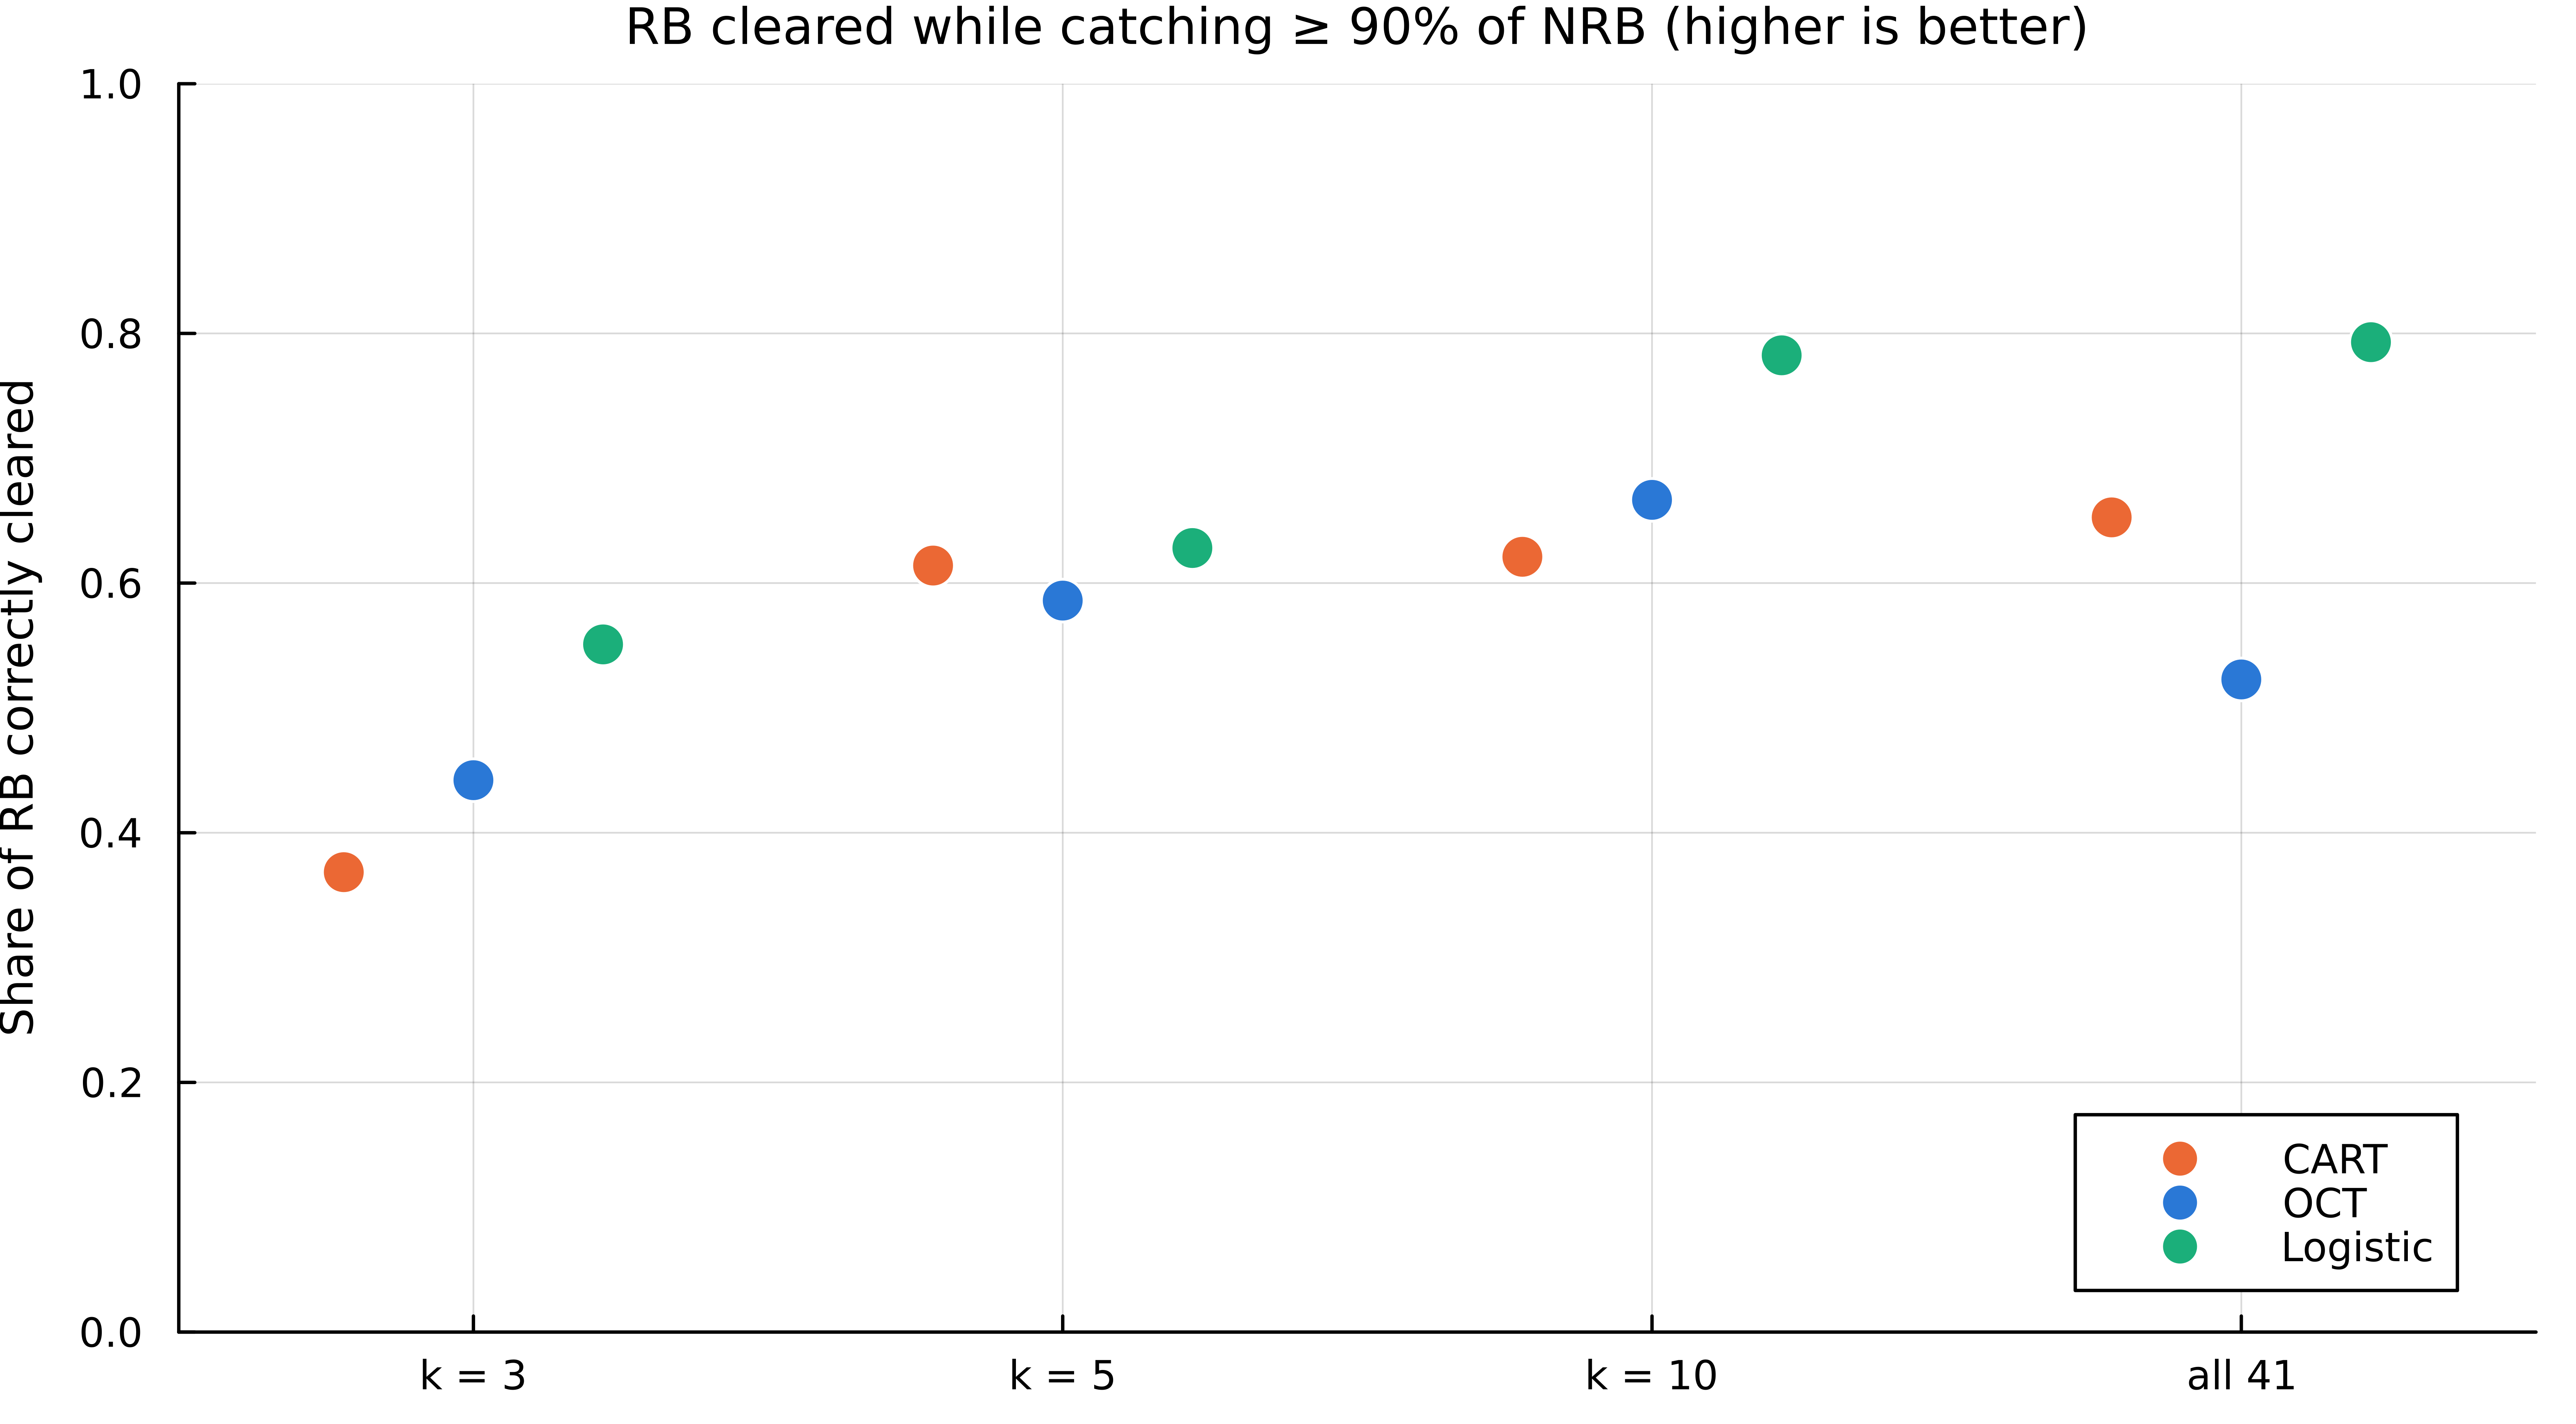

In [18]:
prec = select(results, :set, :model, :thr_prec, :prec_recall, :prec_specificity, :prec_nrb_missed, :prec_rb_cleared)
for c in [:thr_prec, :prec_recall, :prec_specificity]
    prec[!, c] = round.(prec[!, c], digits = 3)
end
println("NRB-first operating point (catch ≥ $(round(Int, 100NRB_RECALL_TARGET))% of NRB), out-of-fold on $(length(y_dev)) chemicals")
show(prec, allrows = true, eltypes = false, summary = false)
println()

fig5 = plot(size = (760, 420), xticks = (1:nS, setlabel.(SETS)), xlims = (0.5, nS + 0.5), ylims = (0, 1),
            ylabel = "Share of RB correctly cleared", legend = :bottomright,
            title = "RB cleared while catching ≥ $(round(Int, 100NRB_RECALL_TARGET))% of NRB (higher is better)")
for (i, m) in enumerate(MODELS)
    v = [filter(r -> r.set == s && r.model == m, results)[1, :] for s in SETS]
    scatter!(fig5, (1:nS) .+ off[i], [r.prec_specificity for r in v];
             color = COLORS[m], markersize = 7, markerstrokecolor = :white, label = m)
end
savefig(fig5, "figures/fig5_nrb_first.png")
fig5

> ### What the NRB-first view shows
> RB chemicals still cleared (out of 285) when each model is set to catch at least 90% of NRB:
>
> | | k = 3 | k = 5 | k = 10 | all 41 |
> |---|---|---|---|---|
> | Logistic | 157 (55%) | 179 (63%) | 223 (78%) | 226 (79%) |
> | OCT | 126 (44%) | 167 (59%) | 190 (67%) | 149 (52%) |
> | CART | 105 (37%) | 175 (61%) | 177 (62%) | 186 (65%) |
>
> - **At k = 5 the three models are nearly tied** (59–63%): as a precautionary screen with 5 descriptors, a tree costs only about 4–12 extra lab tests out of 285 RB chemicals.
> - **Elsewhere the trees fall further behind than balanced accuracy suggested.** At k = 3 the OCT had the best balanced accuracy, but to reach 90% recall it must also flag a large mixed leaf, so it clears only 44% of RB. With all 41, the OCT's threshold drops to 0.175 and it clears 77 fewer RB chemicals than logistic regression.
> - **Why:** a tree's threshold can only move in leaf-sized steps. Hitting a recall target often means flagging an entire leaf that contains many RB chemicals, while logistic regression can stop at exactly the right chemical.
> - **Practical reading:** if a regulator insists on catching 90% of persistent chemicals, a 5-descriptor tree is a reasonable, checkable screen; with more descriptors, logistic regression saves substantially more unnecessary tests.

---
## Part 7b — Depth trade-off

**Figure 6** shows, for each sparsity level, what each allowed tree depth buys: mean CV AUC (top), out-of-fold balanced accuracy (middle) and average number of leaves (bottom). The dashed line is logistic regression at the same k; the star marks the depth the simplicity rule chose. It reads `TREE_DEPTHS` from Part 3, so after changing the depths and rerunning Part 6 it updates by itself.

**How to read it:** if the AUC curve flattens while the leaf count keeps rising, extra depth costs interpretability without buying accuracy.

In [ ]:
ylim_of(v; pad = 0.02) = (minimum(v) - pad, maximum(v) + pad)
lg_rows = filter(r -> r.model == "Logistic", results)
auc_lim = ylim_of(vcat(depth_tbl.cv_auc .- depth_tbl.cv_sd, depth_tbl.cv_auc .+ depth_tbl.cv_sd, lg_rows.cv_auc))
bal_lim = ylim_of(vcat(depth_tbl.cv_bal_acc, lg_rows.cv_bal_acc))
leaf_lim = (0, maximum(depth_tbl.mean_leaves) + 2)
depths = sort(unique(depth_tbl.max_depth))

fig6 = plot(layout = (3, nS), size = (290nS, 780), legend = :bottomright, xticks = depths,
            left_margin = 4Plots.mm, bottom_margin = 3Plots.mm)
for (j, s) in enumerate(SETS)
    lg = filter(r -> r.set == s, lg_rows)[1, :]
    hline!(fig6, [lg.cv_auc]; subplot = j, color = COLORS["Logistic"], ls = :dash, lw = 1.5,
           label = j == 1 ? "Logistic" : "")
    hline!(fig6, [lg.cv_bal_acc]; subplot = nS + j, color = COLORS["Logistic"], ls = :dash, lw = 1.5, label = "")
    for m in TREES
        d = sort(filter(r -> r.set == s && r.model == m, depth_tbl), :max_depth)
        c = d[d.chosen, :]
        plot!(fig6, d.max_depth, d.cv_auc; subplot = j, yerror = d.cv_sd, color = COLORS[m], lw = 2,
              marker = :circle, ms = 4, markerstrokecolor = COLORS[m], label = j == 1 ? m : "")
        scatter!(fig6, c.max_depth, c.cv_auc; subplot = j, marker = :star5, ms = 10, color = COLORS[m],
                 markerstrokecolor = :white, label = (j == 1 && m == TREES[end]) ? "chosen depth" : "")
        plot!(fig6, d.max_depth, d.cv_bal_acc; subplot = nS + j, color = COLORS[m], lw = 2,
              marker = :circle, ms = 4, markerstrokecolor = :white, label = "")
        plot!(fig6, d.max_depth, d.mean_leaves; subplot = 2nS + j, color = COLORS[m], lw = 2,
              marker = :circle, ms = 4, markerstrokecolor = :white, label = "")
    end
    plot!(fig6; subplot = j, title = setlabel(s), ylims = auc_lim, ylabel = j == 1 ? "CV AUC" : "")
    plot!(fig6; subplot = nS + j, ylims = bal_lim, ylabel = j == 1 ? "CV balanced accuracy" : "")
    plot!(fig6; subplot = 2nS + j, ylims = leaf_lim, xlabel = "Maximum depth",
          ylabel = j == 1 ? "Average leaves" : "")
end
savefig(fig6, "figures/fig6_depth_tradeoff.png")
fig6

> ### What the depth trade-off shows
> - **Depth 2 is always too shallow:** CV AUC 0.73–0.77, well below depth 3.
> - **Depth 3 → 4 still adds about 0.02–0.03 AUC** for OCT at k = 5, k = 10 and all 41 (all 41: 0.818 → 0.842), so the curves have not fully flattened at the cap. Balanced accuracy, however, barely moves with all 41 (about 0.795 → 0.798).
> - **Leaves grow fast:** about 4 at depth 2, 6–7 at depth 3 and 8–11 at depth 4. Depth 5 would likely mean 15–20 leaves, which is hard to explain on one slide.
> - **Depth cannot close the gap to logistic regression with many descriptors:** at all 41 the trees are about 0.09 AUC below the dashed line at depth 4. Even if each extra level kept adding 0.02, it would take several more levels, and many more leaves, to get there.
> - **At k = 3 depth matters least:** OCT chose depth 3 because depth 4 added under 0.01 AUC.
>
> **Conclusion:** the depth cap is not what holds the trees back. Their limit is structural: few descriptors per tree and one score per leaf. A one-off check at `TREE_DEPTHS = 2:5` would confirm this, but decide before freezing Part 8 and report it either way.

**The final trees.** The two OCTs most worth explaining in the report: the 3-descriptor tree (most readable) and the all-descriptor tree. Change `key` to view any other (set, model) pair.

In [ ]:
for key in [("k3", "OCT"), ("all", "OCT")]
    lnr = final_models[key].model
    println("\n=== $(key[2]) | $(setlabel(key[1])) | $(tree_leaves(lnr)) leaves | splits on: ",
            join(tree_features(lnr), ", "), " ===")
    println(lnr)
    IAI.write_html("figures/tree_$(key[1])_$(key[2]).html", lnr)   # interactive version for the report
end

> ### Interpreting the trees (fill in after printing)
> For each tree, write 2–4 lines:
> - **The rule for RB:** which path leads to the main RB leaf, and how many training chemicals it holds.
> - **The cleanest NRB rule:** the purest NRB leaf and its share.
> - **The weakest leaf:** the most mixed leaf. This is where errors concentrate and why the NRB-first threshold has to drop so far.
> - **Read splits as properties, not exact descriptors** (Part 2): e.g. a split on SpMax_L means "size/branching", nN means "nitrogen content".

---
## Part 8 — Final parameters selected by cross-validation

These settings are fixed before the test. Every final model was refit on all 844 development chemicals with them; both thresholds come from the out-of-fold predictions: `threshold` maximizes balanced accuracy; `thr_prec` is the NRB-first threshold (catch ≥ 90% of NRB).

In [19]:
params_tbl = select(results, :set, :model, :settings, :leaves, :descriptors_used, :threshold, :thr_prec, :cv_auc, :cv_bal_acc)
params_tbl.threshold  = round.(params_tbl.threshold, digits = 3)
params_tbl.thr_prec   = round.(params_tbl.thr_prec, digits = 3)
params_tbl.cv_auc     = round.(params_tbl.cv_auc, digits = 3)
params_tbl.cv_bal_acc = round.(params_tbl.cv_bal_acc, digits = 3)
println("Final cross-validated parameters (frozen for test)")
show(params_tbl, allrows = true, allcols = true, eltypes = false, summary = false, truncate = 0)
CSV.write("final_parameters.csv", params_tbl)
println()

Final cross-validated parameters (frozen for test)
 Row │ set  model     settings                               leaves   descriptors_used  threshold  thr_prec  cv_auc  cv_bal_acc 
─────┼──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ k3   CART      max_depth=4, minbucket=20, cp=0.00439        6                 3      0.68      0.263   0.819       0.787
   2 │ k3   OCT       max_depth=3, minbucket=20, cp=0.00768        6                 3      0.787     0.246   0.792       0.774
   3 │ k3   Logistic  lambda=1.0                             missing                 3      0.711     0.497   0.83        0.763
   4 │ k5   CART      max_depth=4, minbucket=20, cp=0.0132         5                 3      0.7       0.519   0.809       0.771
   5 │ k5   OCT       max_depth=4, minbucket=20, cp=0.00658        9                 4      0.6       0.239   0.842       0.813
   6 │ k5   Logistic  lambda=10.0                  

> **Freeze check before testing.** Every model at every sparsity level has its settings and both thresholds recorded here and saved to `final_parameters.csv`. Trees mostly chose depth 4 with leaf size 20; logistic regression chose λ = 1 (λ = 10 at k = 5). If you run the depth-5 check, do it before this point, then rerun Parts 6–8 once and do not change anything after Part 9.

---
## Part 9 — Test evaluation (run once)

Set `RUN_TEST = true` only when Part 8 is final. Each final model is applied to the 211 test chemicals with its frozen threshold; nothing is refit or retuned. One table per sparsity level with both operating points (balanced and NRB-first), plus the always-NRB baseline, then two figures: test vs. CV AUC, and test ROC curves. Do not change any setting after seeing these numbers.

In [ ]:
RUN_TEST = false

if RUN_TEST
    test_results = DataFrame(set = String[], model = String[], test_auc = Float64[],
                             test_bal_acc = Float64[], test_recall = Float64[], test_specificity = Float64[],
                             nrb_missed = Int[], rb_cleared = Int[],
                             prec_recall = Float64[], prec_specificity = Float64[], prec_nrb_missed = Int[],
                             cv_auc = Float64[], cv_bal_acc = Float64[])
    test_p = Dict{Tuple{String,String},Vector{Float64}}()
    for s in SETS, m in MODELS
        f = final_models[(s, m)]
        p = f.predict(X_te); test_p[(s, m)] = p
        mt = metrics(p, y_te; t = f.threshold)
        mp = metrics(p, y_te; t = f.thr_prec)
        cv = filter(r -> r.set == s && r.model == m, results)[1, :]
        push!(test_results, (s, m, auc(p, y_te), mt.bal_acc, mt.recall, mt.specificity,
                             mt.nrb_missed, mt.rb_cleared, mp.recall, mp.specificity, mp.nrb_missed,
                             cv.cv_auc, cv.cv_bal_acc))
    end
    for c in [:test_auc, :test_bal_acc, :test_recall, :test_specificity, :prec_recall, :prec_specificity, :cv_auc, :cv_bal_acc]
        test_results[!, c] = round.(test_results[!, c], digits = 3)
    end
    CSV.write("test_results_final.csv", test_results)

    b = metrics(ones(length(y_te)), y_te)
    println("Test set: $(sum(y_te)) NRB, $(length(y_te) - sum(y_te)) RB. ",
            "Always-NRB baseline: balanced accuracy $(b.bal_acc), AUC 0.5\n")
    for s in SETS
        println("=== Test | ", setlabel(s), " ===")
        show(sort(select(filter(r -> r.set == s, test_results), Not(:set)), :test_auc, rev = true),
             allcols = true, eltypes = false, summary = false)
        println("\n")
    end

    # Figure 7: test AUC (filled) next to CV AUC (hollow), within each sparsity level
    fig7 = plot(size = (760, 420), xticks = (1:nS, setlabel.(SETS)), xlims = (0.5, nS + 0.5),
                ylabel = "AUC", legend = :bottomright,
                title = "Test AUC (filled) vs. cross-validation AUC (hollow)")
    for (i, m) in enumerate(MODELS)
        v = [filter(r -> r.set == s && r.model == m, test_results)[1, :] for s in SETS]
        scatter!(fig7, (1:nS) .+ off[i], [r.cv_auc for r in v]; color = :white, markerstrokecolor = COLORS[m],
                 markerstrokewidth = 2, markersize = 7, label = "")
        scatter!(fig7, (1:nS) .+ off[i], [r.test_auc for r in v]; color = COLORS[m], markersize = 7,
                 markerstrokecolor = :white, label = m)
    end
    savefig(fig7, "figures/fig7_test_vs_cv_auc.png")
    display(fig7)

    # Figure 8: test ROC curves
    fig8 = plot(layout = (1, nS), size = (300nS, 340), legend = :bottomright, left_margin = 4Plots.mm,
                bottom_margin = 6Plots.mm)
    for (j, s) in enumerate(SETS)
        plot!(fig8, [0, 1], [0, 1]; subplot = j, color = :gray75, ls = :dot, label = "")
        hline!(fig8, [NRB_RECALL_TARGET]; subplot = j, color = :gray50, ls = :dash, label = "")
        for m in MODELS
            fpr, tpr = roc_points(test_p[(s, m)], y_te)
            plot!(fig8, fpr, tpr; subplot = j, color = COLORS[m], lw = 2, label = j == 1 ? m : "")
        end
        plot!(fig8; subplot = j, title = "Test | " * setlabel(s), xlabel = "Share of RB flagged as NRB",
              ylabel = j == 1 ? "Share of NRB caught" : "", xlims = (0, 1), ylims = (0, 1))
    end
    savefig(fig8, "figures/fig8_test_roc.png")
    display(fig8)
else
    println("Test evaluation is switched off (RUN_TEST = false).")
end